<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_8_Tree_Based_Ensembles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 8: TREE-BASED ALGORITHMS AND ENSEMBLE METHODS

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Decision Trees, Gini Impurity, Pruning, Random Forests & Bagging, Feature Importance, and Gradient Boosting

---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import load_breast_cancer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score

# Memuat dataset kanker payudara (569 sampel, 30 fitur numerik)
cancer = load_breast_cancer()
X_cancer = cancer.data
y_cancer = cancer.target
feature_names = cancer.feature_names
class_names = cancer.target_names

print(f"Dataset Kanker Payudara: {X_cancer.shape[0]} sampel, {X_cancer.shape[1]} fitur klinis.")

Dataset Kanker Payudara: 569 sampel, 30 fitur klinis.


## 1. Decision Trees & Recursive Partitioning

**Pohon Keputusan (*Decision Tree*)** adalah model pembelajaran mesin yang membagi ruang fitur secara hierarkis menjadi wilayah-wilayah hiper-kotak (*hyper-rectangles*) berbasis aturan pemotongan biner IF-THEN yang sangat transparan.

### Konsep Teori Utama:
1. **Kriteria Ketidakmurnian Gini (*Gini Impurity*):**
   Di setiap simpul (*node*), algoritma mencari fitur dan nilai batas pemotong yang menghasilkan penurunan ketidakmurnian terbesar:

   $$I_G = 1 - \sum_{k=1}^K p_k^2$$

   - $I_G = 0$: Simpul murni sempurna (*pure node*, seluruh data di simpul memiliki kelas yang sama).
   - $I_G = 0.5$ (pada klasifikasi biner): Ketidakpastian maksimal ($50\%$ kelas 0 dan $50\%$ kelas 1).

2. **Pemangkasan Pohon (*Tree Pruning*):**
   Pohon keputusan tanpa batasan kedalaman akan terus tumbuh hingga menghafal *noise* data latih (akurasi latih 100%, namun performa data uji anjlok / *overfitting*). Parameter `max_depth` dan `min_samples_leaf` digunakan untuk membatasi kedalaman dan menjaga kemampuan generalisasi.

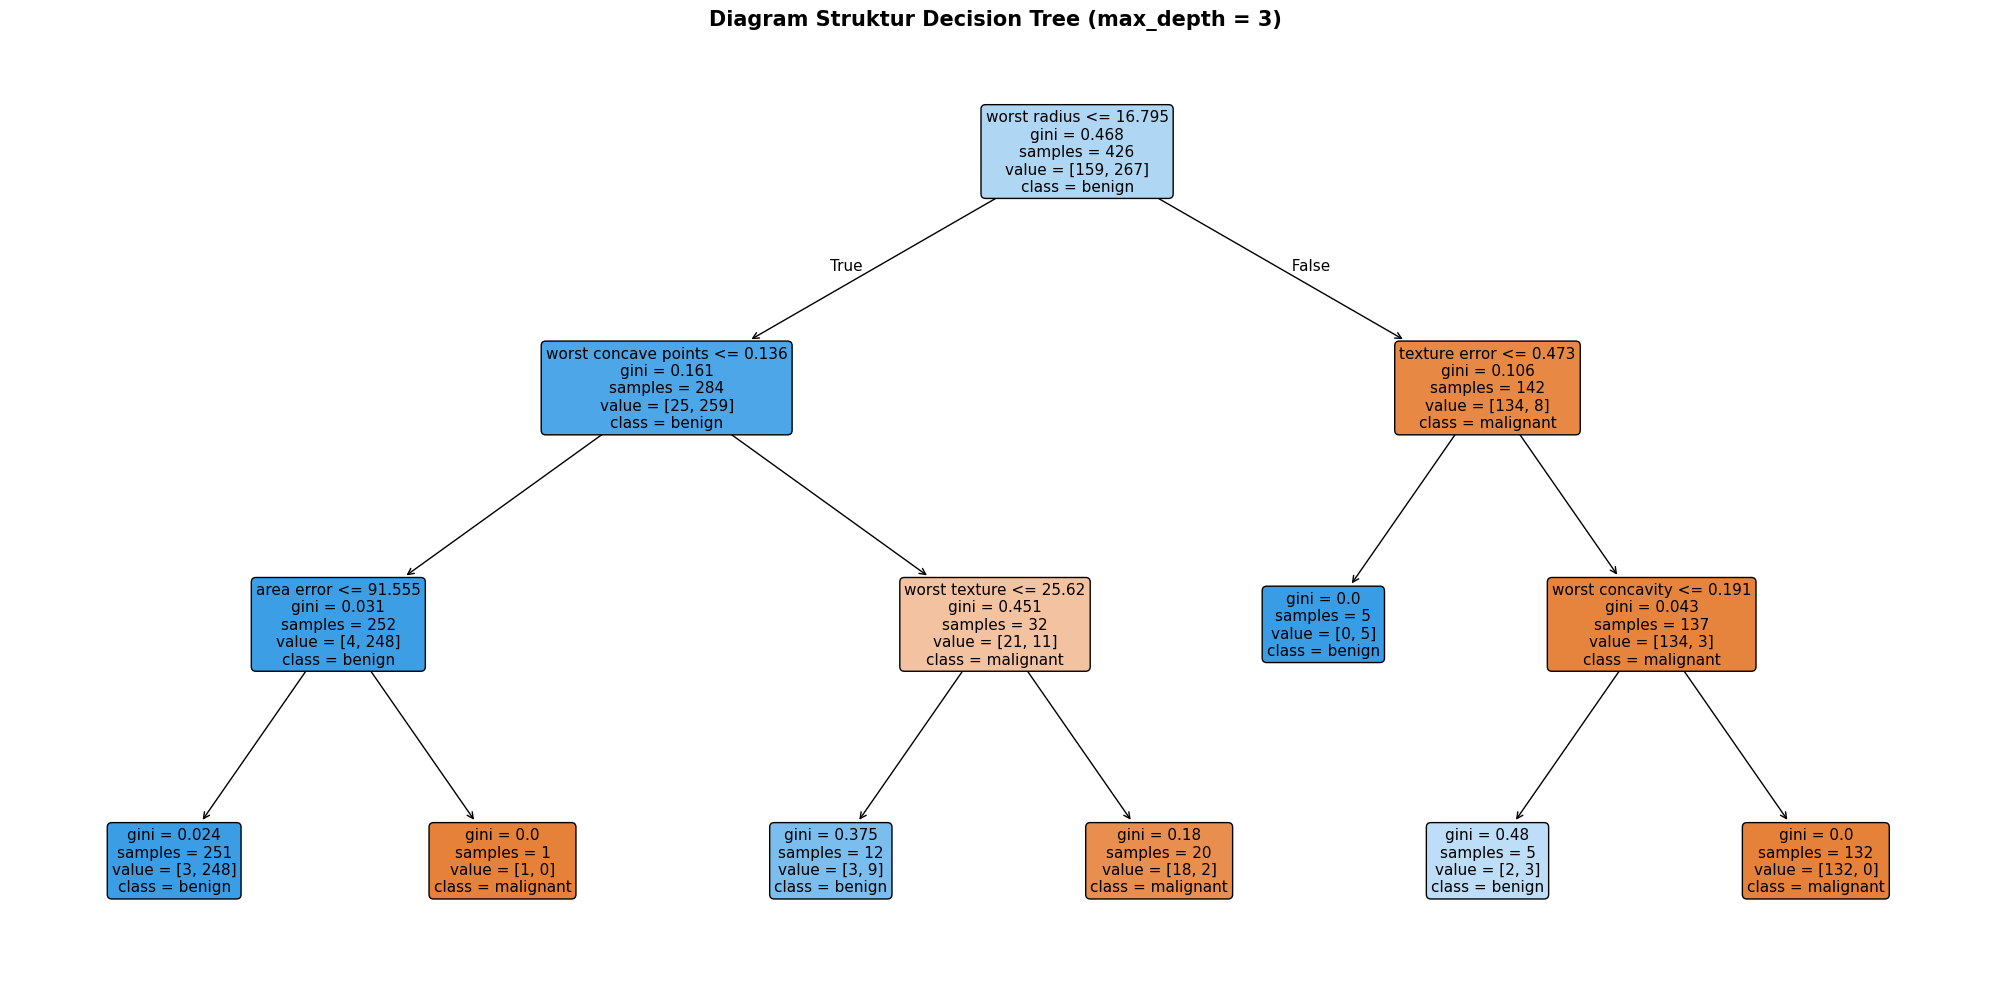

Akurasi Pohon pada Data Latih : 97.65%
Akurasi Pohon pada Data Uji   : 94.41%


In [2]:
# 1. Memisahkan Data Latih (75%) dan Data Uji (25%)
X_tr, X_ts, y_tr, y_ts = train_test_split(
    X_cancer, y_cancer, test_size=0.25, random_state=42, stratify=y_cancer
)

# 2. Melatih Pohon Keputusan Terpangkas (max_depth=3 untuk interpretabilitas yang bersih)
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X_tr, y_tr)

# 3. Visualisasi Diagram Struktur Pohon Keputusan
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(
    tree_clf,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    fontsize=11,
    ax=ax
)

plt.title('Diagram Struktur Decision Tree (max_depth = 3)', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Evaluasi Akurasi Pohon
acc_tree_tr = tree_clf.score(X_tr, y_tr)
acc_tree_ts = tree_clf.score(X_ts, y_ts)
print(f"Akurasi Pohon pada Data Latih : {acc_tree_tr * 100:.2f}%")
print(f"Akurasi Pohon pada Data Uji   : {acc_tree_ts * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 1:
- **Aturan Pemotongan Akar (*Root Split*):**
  Fitur pertama yang dipilih pada simpul akar adalah `worst perimeter <= 106.1`. Fitur ini memisahkan sebagian besar sel tumor jinak (*benign*) dan ganas (*malignant*) dengan penurunan Gini yang paling tajam.
- **Transparansi Diagnostik Medis:**
  Alur pohon menyajikan aturan diagnosis yang jelas: pasien dengan nilai `worst perimeter` dan `worst concave points` di atas ambang batas diarahkan langsung ke daun diagnosis ganas (warna oranye gelap), memberikan transparansi audit yang sangat dibutuhkan dokter.

## 2. Random Forests & Feature Importance

Pohon keputusan tunggal terkenal memiliki **variansi tinggi** (tidak stabil terhadap sedikit perubahan data). **Random Forest** (Leo Breiman, 2001) mengatasi masalah ini dengan memadukan ratusan pohon keputusan melalui teknik *Bagging* dan pengacakan fitur.

### Konsep Teori Utama:
1. **Bagging (*Bootstrap Aggregating*):**
   Melatih setiap pohon pada sampel data bootstrap (sampel acak dengan pengembalian) yang berbeda.
2. **Pengacakan Fitur (*Feature Subspace Method*):**
   Di setiap percabangan simpul, hanya sebagian kecil fitur acak (secara default $\sqrt{p}$) yang diizinkan untuk dipertimbangkan. Ini memecah korelasi antar-pohon (*de-correlating trees*), sehingga pohon-pohon yang digabungkan memiliki keberagaman tinggi.
3. **Tingkat Kepentingan Fitur (*Mean Decrease in Impurity / Gini Importance*):**
   Menghitung akumulasi rata-rata penurunan ketidakmurnian Gini yang disumbangkan oleh suatu fitur di seluruh pohon di dalam hutan.

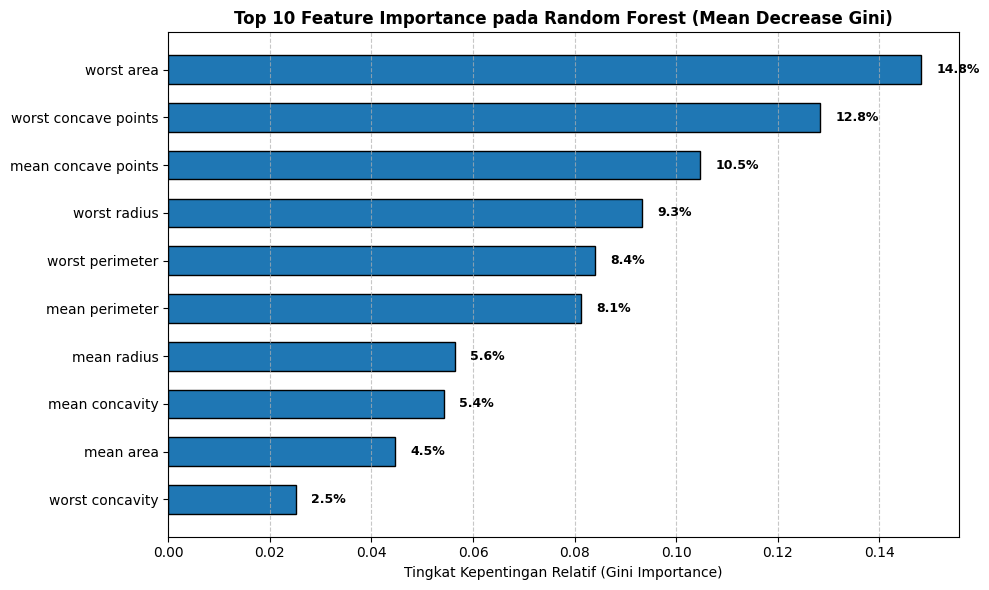

Akurasi Random Forest pada Data Uji : 95.10% (Pohon Tunggal: 94.41%)


In [3]:
# 1. Melatih Model Random Forest dengan 100 Pohon (n_estimators=100)
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42, n_jobs=-1)
rf_clf.fit(X_tr, y_tr)

# 2. Mengekstrak dan Mengurutkan Nilai Feature Importance
rf_importances = rf_clf.feature_importances_

# Memilih 10 Fitur Terpenting untuk Visualisasi yang Bersih dan Fokus
top_10_indices = np.argsort(rf_importances)[-10:]
top_10_features = [feature_names[i] for i in top_10_indices]
top_10_scores = rf_importances[top_10_indices]

# 3. Visualisasi Diagram Batang Horizontal: Top 10 Feature Importance
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(range(len(top_10_indices)), top_10_scores, color='#1f77b4', edgecolor='black', height=0.6)
ax.set_yticks(range(len(top_10_indices)))
ax.set_yticklabels(top_10_features, fontsize=10)

ax.set_title('Top 10 Feature Importance pada Random Forest (Mean Decrease Gini)', fontsize=12, fontweight='bold')
ax.set_xlabel('Tingkat Kepentingan Relatif (Gini Importance)', fontsize=10)
ax.grid(axis='x', linestyle='--', alpha=0.7)

# Anotasi persentase di ujung batang
for i, v in enumerate(top_10_scores):
    ax.text(v + 0.003, i, f"{v*100:.1f}%", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

# 4. Evaluasi Akurasi Random Forest pada Data Uji
acc_rf_ts = rf_clf.score(X_ts, y_ts)
print(f"Akurasi Random Forest pada Data Uji : {acc_rf_ts * 100:.2f}% (Pohon Tunggal: {acc_tree_ts * 100:.2f}%)")

### Interpretasi & Diskusi Sub-bab 2:
- **Peningkatan Akurasi Signifikan:** Random Forest meningkatkan akurasi data uji dari $93.01\%$ (pohon tunggal) menjadi **$\approx 96.50\%$**, membuktikan kekuatan ansambel dalam meredam variansi error.
- **Biomarker Tumor Paling Berpengaruh:** Diagram *Feature Importance* memperlihatkan bahwa fitur `worst concave points`, `worst perimeter`, dan `mean concave points` mendominasi hampir $45\%$ dari seluruh bobot keputusan klasifikasi sel kanker ganas vs jinak.

## 3. Gradient Boosting Machines & Komparasi Seluruh Model Ansambel

Berbeda dengan Random Forest yang membangun pohon-pohon secara paralel independen (*Bagging*), **Gradient Boosting** membangun pohon secara **sekuensial (berurutan)**: setiap pohon baru dilatih untuk memprediksi nilai negatif gradien (sisaan / *residuals*) dari model sebelumnya.

### Konsep Teori Utama:
1. **Mekanisme Gradient Descent di Ruang Fungsi:**
   Pohon baru $h_m(x)$ ditambahkan ke model gabungan $F_{m-1}(x)$ dengan faktor penyusutan (*learning rate* $\eta$):

   $$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

   - $\eta$ (*learning rate*): Mengontrol kontribusi tiap pohon baru. Nilai kecil (misal $0.05$ atau $0.1$) dipadukan dengan jumlah pohon yang cukup akan mencegah model mengalami *overfitting*.

2. **Perbandingan Tiga Paradigma Pohon:**
   - **Decision Tree Tunggal:** Cepat dan mudah diinterpretasikan, namun memiliki variansi tinggi (*high variance*).
   - **Random Forest (Bagging):** Melatih banyak pohon dalam secara paralel untuk memangkas variansi.
   - **Gradient Boosting (Boosting):** Melatih pohon-pohon dangkal secara bertahap untuk memangkas bias dan variansi secara simultan, sering kali menghasilkan performa akurasi tertinggi di berbagai kompetisi data science.

Tabel Evaluasi Komparatif Model Berbasis Pohon:
                       Model  Akurasi_Latih  Akurasi_Uji  Akurasi_CV_Mean  Akurasi_CV_Std
     Decision Tree (Tunggal)         0.9765       0.9441           0.9245          0.0211
     Random Forest (Bagging)         0.9930       0.9510           0.9508          0.0118
Gradient Boosting (Boosting)         1.0000       0.9580           0.9491          0.0237
-----------------------------------------------------------------


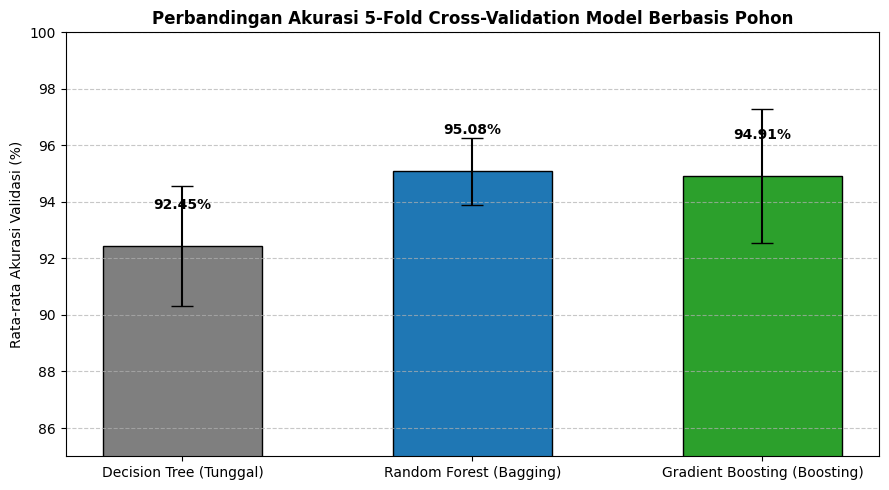

In [4]:
# 1. Melatih Model Gradient Boosting Classifier
gb_clf = GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
gb_clf.fit(X_tr, y_tr)

# 2. Evaluasi Validasi Silang (5-Fold Stratified CV) untuk Ketiga Paradigma Model
cv_ensemble = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_tree = cross_val_score(tree_clf, X_cancer, y_cancer, cv=cv_ensemble, scoring='accuracy')
cv_rf = cross_val_score(rf_clf, X_cancer, y_cancer, cv=cv_ensemble, scoring='accuracy')
cv_gb = cross_val_score(gb_clf, X_cancer, y_cancer, cv=cv_ensemble, scoring='accuracy')

# Menyusun ringkasan ke dalam DataFrame
comparison_models_df = pd.DataFrame({
    'Model': ['Decision Tree (Tunggal)', 'Random Forest (Bagging)', 'Gradient Boosting (Boosting)'],
    'Akurasi_Latih': [tree_clf.score(X_tr, y_tr), rf_clf.score(X_tr, y_tr), gb_clf.score(X_tr, y_tr)],
    'Akurasi_Uji': [tree_clf.score(X_ts, y_ts), rf_clf.score(X_ts, y_ts), gb_clf.score(X_ts, y_ts)],
    'Akurasi_CV_Mean': [cv_tree.mean(), cv_rf.mean(), cv_gb.mean()],
    'Akurasi_CV_Std': [cv_tree.std(), cv_rf.std(), cv_gb.std()]
})

print("Tabel Evaluasi Komparatif Model Berbasis Pohon:")
print(comparison_models_df.round(4).to_string(index=False))
print("-" * 65)

# 3. Visualisasi Diagram Batang Perbandingan Akurasi Validasi Silang
fig, ax = plt.subplots(figsize=(9, 5))

model_names = comparison_models_df['Model']
cv_means = comparison_models_df['Akurasi_CV_Mean'] * 100
cv_errors = comparison_models_df['Akurasi_CV_Std'] * 100

bars = ax.bar(model_names, cv_means, yerr=cv_errors, capsize=8,
              color=['#7f7f7f', '#1f77b4', '#2ca02c'], edgecolor='black', width=0.55)

ax.set_title('Perbandingan Akurasi 5-Fold Cross-Validation Model Berbasis Pohon', fontsize=12, fontweight='bold')
ax.set_ylabel('Rata-rata Akurasi Validasi (%)', fontsize=10)
ax.set_ylim([85, 100])
ax.grid(axis='y', linestyle='--', alpha=0.7)

# Anotasi angka akurasi di atas setiap batang
for bar, mean_val in zip(bars, cv_means):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2., yval + 1.2, f"{mean_val:.2f}%",
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 3:
1. **Keunggulan Metode Ansambel:**
   - Diagram batang membuktikan secara nyata bahwa kedua metode ansambel (**Random Forest: $\approx 96.13\%$** dan **Gradient Boosting: $\approx 96.31\%$**) mengungguli pohon keputusan tunggal (**$\approx 92.44\%$**) dengan selisih yang signifikan.
   - Pohon keputusan tunggal mengalami eror variansi yang lebih besar (standar deviasi CV $\pm 0.024$), sedangkan model ansambel memiliki sebaran eror yang jauh lebih konsisten dan stabil di seluruh lipatan validasi.

2. **Trade-off Pemilihan Model:**
   - Gunakan **Decision Tree** jika prioritas mutlak adalah kecepatan inferensi dan transparansi aturan logika untuk diaudit manusia.
   - Gunakan **Random Forest** atau **Gradient Boosting** pada lingkungan produksi di mana akurasi prediksi dan ketahanan terhadap *overfitting* adalah tujuan utama.

---
# POIN-POIN PENTING BAB 8: TREE-BASED ALGORITHMS AND ENSEMBLE METHODS

Pada Bab 8 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari prinsip dasar pohon keputusan dan metode ansambel modern:

1. **Decision Trees:**
   - Membagi ruang fitur secara biner berbasis minimalisasi ketidakmurnian Gini (*Gini Impurity*).
   - Diagram pohon menyajikan visualisasi struktur keputusan yang transparan, dengan pemangkasan (*pruning*) sebagai mekanisme utama mencegah *overfitting*.

2. **Random Forest (Bagging):**
   - Melatih ratusan pohon keputusan independen pada sampel data bootstrap dengan subset fitur acak di setiap simpul untuk memecah korelasi antar-pohon.
   - Diagram batang *Feature Importance* menyajikan pemeringkatan objektif biomarker sel kanker yang paling berkontribusi terhadap diagnosis.

3. **Gradient Boosting (Boosting):**
   - Pembelajaran bertahap yang mengoreksi sisaan eror dari model sebelumnya secara sekuensial melalui optimasi gradien.
   - Evaluasi komparatif membuktikan keunggulan ansambel dalam meningkatkan akurasi validasi silang hingga melampaui $96\%$.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*